# Hospital Consultation Forecasting using XGBoost

This notebook demonstrates monthly consultation forecasting across six consolidated channels. The included sample workbook is synthetic and contains 11 original channel categories. Upload a compatible Excel workbook with a `Sheet1` sheet and the columns used below.

**Privacy:** Do not upload real hospital or patient data to a public repository.


Saving synthetic_consultation_data.xlsx to synthetic_consultation_data.xlsx
Data loaded successfully
Data range: 2023-01-01 00:00:00 to 2026-12-31 00:00:00

Original channels:
['Cash', 'Clinic', 'Corporate', 'ECHS', 'EWS', 'International', 'NHA-CGHS', 'NHA-PSU', 'PSU', 'Research', 'TPA']

MODEL PERFORMANCE COMPARISON


,Model,Channel,MAE,RMSE,WAPE (%),MAPE (%),R2
0,XGBoost,Cash,333.90,408.34,1.52,1.51,0.86
1,XGBoost,CGHS,51.61,64.19,2.20,2.21,0.73
2,XGBoost,Corporate,83.47,94.03,3.56,3.55,0.38
3,XGBoost,EWS,84.37,106.96,3.63,3.57,0.25
4,XGBoost,International,31.31,41.97,5.18,5.00,-0.12
5,XGBoost,TPA,2.43,3.14,22.96,23.03,-0.40
6,XGBoost,Grand Total,393.11,479.19,1.33,1.31,0.85
7,Seasonal Naive,Cash,295.00,421.86,1.34,1.34,0.85
8,Seasonal Naive,CGHS,44.50,52.92,1.90,1.88,0.82
9,Seasonal Naive,Corporate,87.00,98.51,3.71,3.75,0.32



HIGHEST XGBOOST CHANNEL-MONTH ERRORS


,Month,Channel,Actual,XGBoost Predicted,XGBoost APE (%)
41,Jul 2026,TPA,7.0,11.55,65.00
23,Apr 2026,TPA,15.0,9.02,39.88
17,Mar 2026,TPA,9.0,5.59,37.84
29,May 2026,TPA,14.0,9.15,34.67
16,Mar 2026,International,681.0,575.77,15.45
47,Aug 2026,TPA,10.0,11.52,15.18
11,Feb 2026,TPA,11.0,9.39,14.66
59,Oct 2026,TPA,12.0,10.62,11.50
50,Sep 2026,Corporate,2307.0,2114.71,8.34
3,Jan 2026,EWS,2603.0,2390.60,8.16



OVERALL MODEL COMPARISON
XGBoost WAPE: 1.33 %
Seasonal Naive WAPE: 1.4 %

XGBoost performs better than Seasonal Naive.


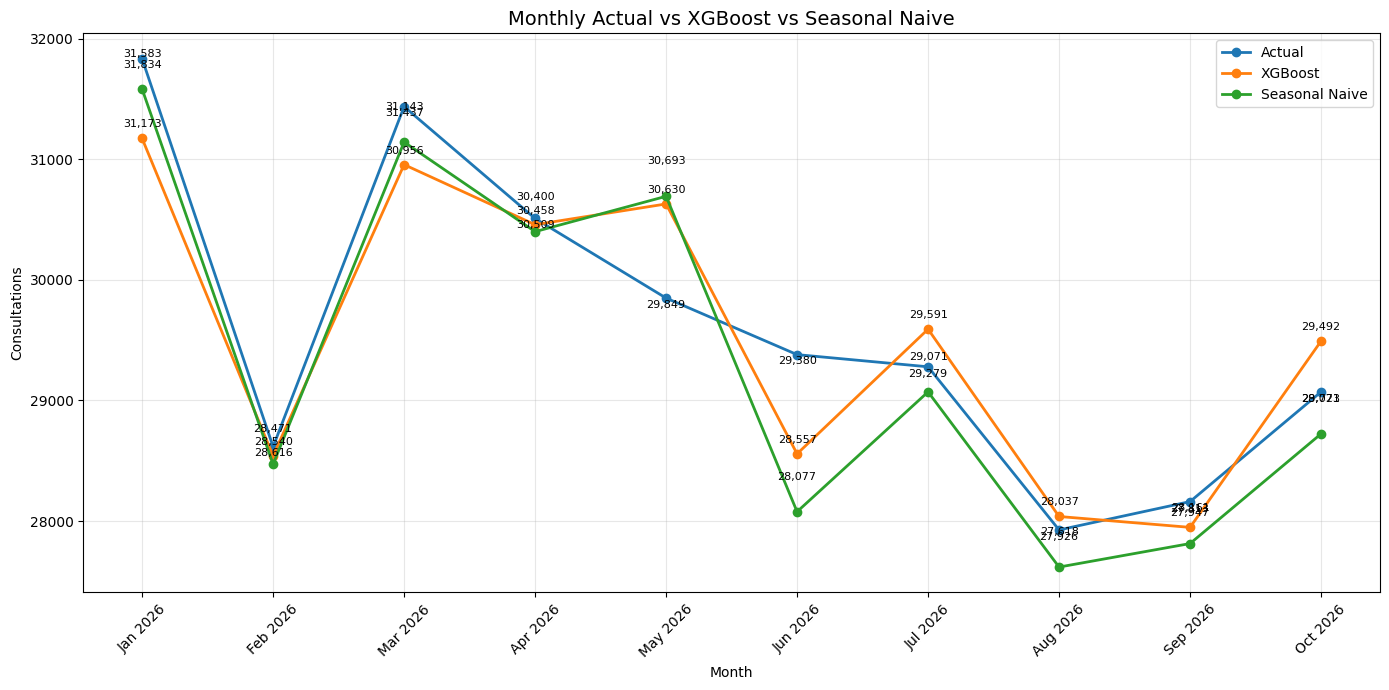

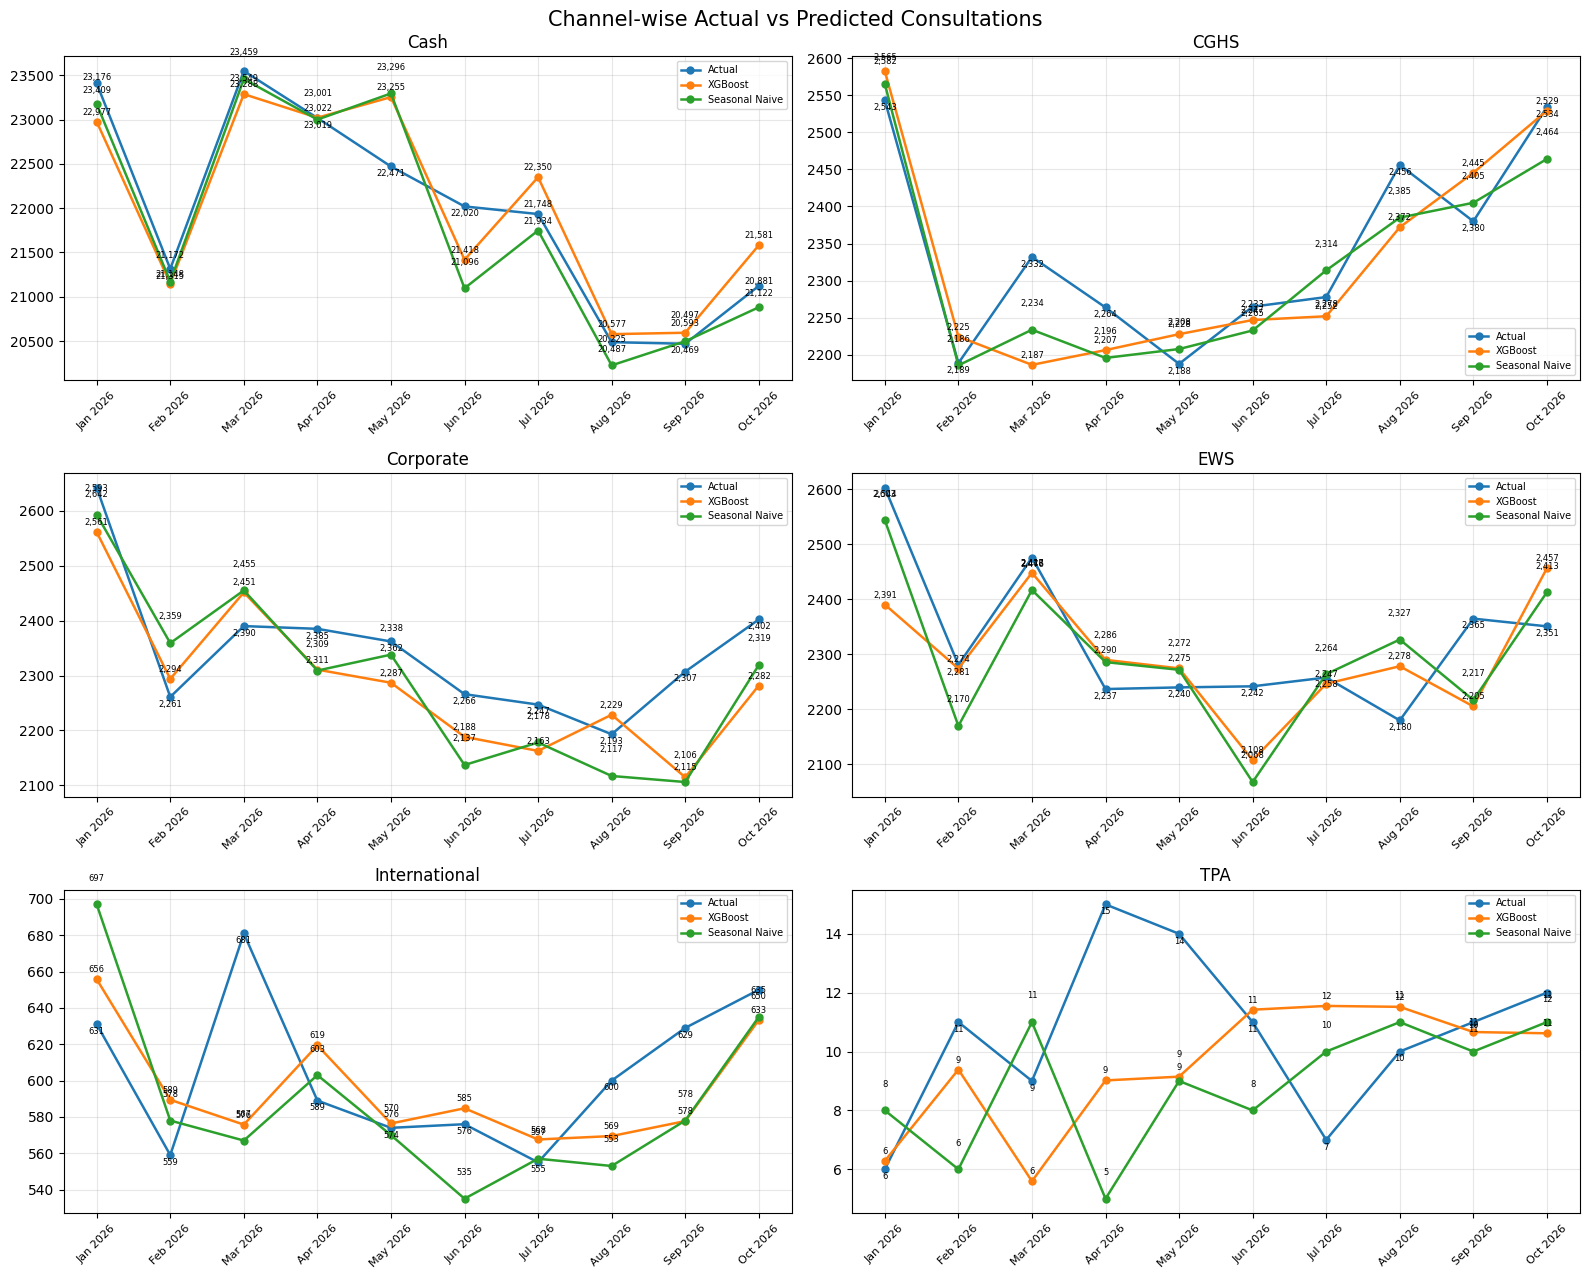

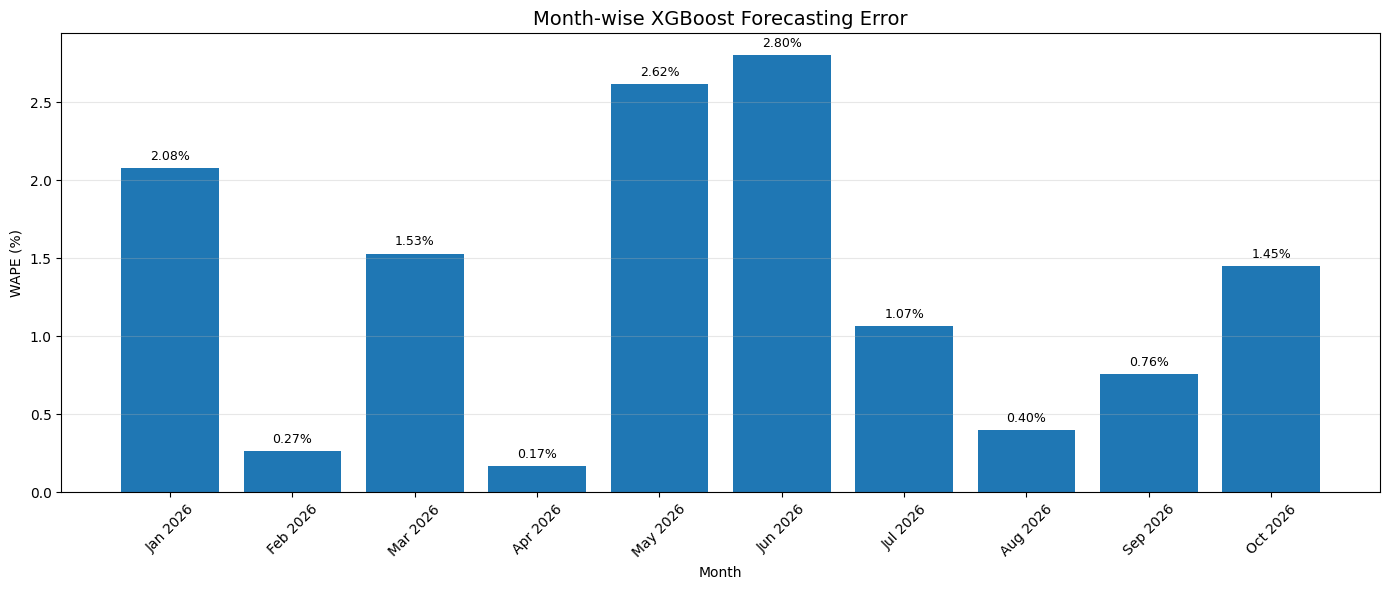


HOSPITAL CONSULTATION FORECASTING - XGBOOST

Select a month and click Predict Month.
Predict multiple months before clicking Give Excel.


Dropdown(description='Select Month:', layout=Layout(width='300px'), options=(('January 2026', '2026-01-01'), (…

Button(button_style='primary', description='Predict Month', icon='calculator', style=ButtonStyle())

Button(button_style='success', description='Give Excel', icon='file-excel', style=ButtonStyle())

Output()

In [1]:

!pip install xgboost openpyxl ipywidgets -q

import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, clear_output
from xgboost import XGBRegressor
from google.colab import files
from openpyxl.styles import Font, Alignment
from openpyxl.utils import get_column_letter

warnings.filterwarnings("ignore")


# ==========================================
# 1. LOAD EXCEL DATA
# ==========================================

uploaded = files.upload()
FILE = list(uploaded.keys())[0]

D = pd.read_excel(FILE, sheet_name="Sheet1")

D["Date"] = pd.to_datetime(D["Date"], errors="coerce")
D["Nos"] = pd.to_numeric(D["Nos"], errors="coerce").fillna(0)
D["companychannel"] = D["companychannel"].astype(str).str.strip()

D = D.dropna(subset=["Date"])

LAST = D["Date"].max()

print("Data loaded successfully")
print("Data range:", D["Date"].min(), "to", LAST)


# ==========================================
# 2. CHANNEL MAPPING
# ==========================================

channel_mapping = {
    "CASH": "Cash",
    "Cash": "Cash",
    "Clinic": "Cash",
    "Embassy": "Cash",
    "Research": "Cash",
    "Corporate": "Corporate",
    "ECHS": "CGHS",
    "NHA-CGHS": "CGHS",
    "NHA-PSU": "CGHS",
    "PSU": "CGHS",
    "EWS": "EWS",
    "International": "International",
    "TPA": "TPA"
}

D["MainChannel"] = D["companychannel"].map(channel_mapping)

unknown = D.loc[
    D["MainChannel"].isna(),
    "companychannel"
].unique()

if len(unknown) > 0:
    raise ValueError(f"Unmapped channels found: {list(unknown)}")

channels = [
    "Cash",
    "CGHS",
    "Corporate",
    "EWS",
    "International",
    "TPA"
]

print("\nOriginal channels:")
print(sorted(D["companychannel"].unique()))


# ==========================================
# 3. DAILY DATA AGGREGATION
# ==========================================

D = (
    D.groupby(["Date", "MainChannel"])["Nos"]
    .sum()
    .unstack(fill_value=0)
)

D = D.reindex(columns=channels, fill_value=0)

D = D.asfreq("D").fillna(0)

# Sunday = zero
D.loc[D.index.dayofweek == 6, :] = 0


# ==========================================
# 4. MONTHLY ACTUAL DATA
# ==========================================

monthly_actual = D.resample("MS").sum()

monthly_actual.index = (
    monthly_actual.index.to_period("M").to_timestamp()
)


# ==========================================
# 5. NOVEMBER FULL-MONTH ESTIMATE
# Used only for December training
# ==========================================

NOV = pd.Timestamp("2026-11-01")

def estimate_full_november(channel):

    history = D.loc[
        D.index <= pd.Timestamp("2026-10-31")
    ].tail(364)

    weights = history.groupby(
        history.index.dayofweek
    )[channel].mean()

    weights = weights.reindex(range(7)).fillna(0)

    if weights.mean() == 0:
        weights[:] = 1

    weights = weights / weights.mean()

    observed_end = min(
        LAST,
        pd.Timestamp("2026-11-30")
    )

    if observed_end < NOV:
        return 0

    observed_dates = pd.date_range(
        NOV,
        observed_end,
        freq="D"
    )

    full_dates = pd.date_range(
        NOV,
        "2026-11-30",
        freq="D"
    )

    actual_sum = D.loc[
        NOV:observed_end,
        channel
    ].sum()

    observed_weight = sum(
        weights[d.dayofweek] for d in observed_dates
    )

    full_weight = sum(
        weights[d.dayofweek] for d in full_dates
    )

    if observed_weight == 0:
        return actual_sum

    return actual_sum / observed_weight * full_weight


november_estimates = {
    ch: estimate_full_november(ch)
    for ch in channels
}


# ==========================================
# 6. XGBOOST FEATURE CREATION
# ==========================================

def make_features(series, target_date):

    values = series.values

    if len(values) < 12:
        raise ValueError("At least 12 months of history required.")

    target_date = pd.Timestamp(target_date)

    row = {}

    for lag in [1, 2, 3, 6, 12]:
        row[f"lag_{lag}"] = values[-lag]

    row["rolling_3"] = np.mean(values[-3:])
    row["rolling_6"] = np.mean(values[-6:])
    row["rolling_12"] = np.mean(values[-12:])

    row["month"] = target_date.month
    row["year"] = target_date.year

    row["month_sin"] = np.sin(
        2 * np.pi * target_date.month / 12
    )

    row["month_cos"] = np.cos(
        2 * np.pi * target_date.month / 12
    )

    row["trend"] = len(values)

    return pd.DataFrame([row])


# ==========================================
# 7. XGBOOST MODEL
# ==========================================

def xgb_forecast(series, target_date):

    series = series.dropna().astype(float)

    if len(series) < 24:
        raise ValueError("Not enough monthly history.")

    X_train = []
    y_train = []

    for i in range(12, len(series)):

        previous = series.iloc[:i]

        target = series.index[i]

        features = make_features(
            previous,
            target
        )

        X_train.append(features.iloc[0].values)
        y_train.append(series.iloc[i])

    X_train = np.array(X_train)
    y_train = np.array(y_train)

    model = XGBRegressor(
        n_estimators=250,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.85,
        colsample_bytree=0.85,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    future_features = make_features(
        series,
        target_date
    )

    prediction = model.predict(future_features)[0]

    return max(0, float(prediction))


# ==========================================
# 8. GET TRAINING DATA
# ==========================================

def get_training_series(channel, target):

    target = pd.Timestamp(target)

    series = monthly_actual[channel].copy()

    series = series.loc[
        series.index < target
    ]

    if target == pd.Timestamp("2026-12-01"):

        series.loc[NOV] = november_estimates[channel]

        series = series.sort_index()

    return series


# ==========================================
# 9. FORECAST ONE MONTH
# ==========================================

def forecast_month(target):

    target = pd.Timestamp(target)

    result = {}

    for ch in channels:

        history = get_training_series(
            ch,
            target
        )

        result[ch] = xgb_forecast(
            history,
            target
        )

    return result


# ==========================================
# 10. ACTUAL TABLE - 2026
# ==========================================

actual_months = pd.date_range(
    "2026-01-01",
    "2026-12-01",
    freq="MS"
)

Actual = pd.DataFrame(
    index=channels,
    columns=[
        m.strftime("%b %Y")
        for m in actual_months
    ],
    dtype=float
)

for month in actual_months:

    month_end = month + pd.offsets.MonthEnd(0)

    actual_end = min(month_end, LAST)

    if month <= LAST.to_period("M").to_timestamp():

        label = month.strftime("%b %Y")

        if actual_end < month_end:

            label = (
                month.strftime("%b %Y")
                + f" (1-{actual_end.day})"
            )

        values = D.loc[
            month:actual_end
        ].sum()

        for ch in channels:
            Actual.loc[ch, label] = values[ch]

Actual["Grand Total"] = Actual.sum(
    axis=1,
    min_count=1
)


# ==========================================
# 11. WALK-FORWARD VALIDATION
# XGBOOST VS SEASONAL NAIVE
# ==========================================

validation_rows = []

validation_months = pd.date_range(
    "2026-01-01",
    "2026-10-01",
    freq="MS"
)

for month in validation_months:

    try:

        xgb_result = forecast_month(month)

        previous_year_month = (
            month - pd.DateOffset(years=1)
        )

        actual_values = D.loc[
            month:month + pd.offsets.MonthEnd(0)
        ].sum()

        for ch in channels:

            actual_value = float(actual_values[ch])

            xgb_prediction = float(xgb_result[ch])

            seasonal_prediction = float(
                monthly_actual.loc[previous_year_month, ch]
            )

            validation_rows.append({
                "Month": month.strftime("%b %Y"),
                "Channel": ch,
                "Actual": actual_value,
                "XGBoost Predicted": xgb_prediction,
                "Seasonal Naive Predicted": seasonal_prediction,
                "XGBoost Error": abs(
                    actual_value - xgb_prediction
                ),
                "Baseline Error": abs(
                    actual_value - seasonal_prediction
                )
            })

    except Exception as e:

        print(
            "Validation skipped:",
            month.strftime("%b %Y"),
            e
        )


Validation = pd.DataFrame(validation_rows)


# ==========================================
# 12. MODEL PERFORMANCE STATISTICS
# ==========================================

def calculate_metrics(data, prediction_column):

    actual = data["Actual"].astype(float).values

    predicted = data[prediction_column].astype(float).values

    errors = actual - predicted

    absolute_errors = np.abs(errors)

    mae = np.mean(absolute_errors)

    rmse = np.sqrt(np.mean(errors ** 2))

    total_actual = np.sum(actual)

    wape = (
        np.sum(absolute_errors) / total_actual * 100
        if total_actual > 0 else np.nan
    )

    valid = actual > 0

    mape = (
        np.mean(
            absolute_errors[valid] / actual[valid] * 100
        )
        if np.any(valid) else np.nan
    )

    if (
        len(actual) > 1
        and np.sum((actual - np.mean(actual)) ** 2) > 0
    ):

        r2 = 1 - (
            np.sum(errors ** 2) /
            np.sum((actual - np.mean(actual)) ** 2)
        )

    else:

        r2 = np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape,
        "MAPE (%)": mape,
        "R2": r2
    }


summary_rows = []

if not Validation.empty:

    for model_name, prediction_column in [
        ("XGBoost", "XGBoost Predicted"),
        ("Seasonal Naive", "Seasonal Naive Predicted")
    ]:

        for channel in channels:

            channel_data = Validation[
                Validation["Channel"] == channel
            ]

            metrics = calculate_metrics(
                channel_data,
                prediction_column
            )

            metrics["Model"] = model_name
            metrics["Channel"] = channel

            summary_rows.append(metrics)

        overall_data = (
            Validation.groupby("Month", as_index=False)
            .agg(
                Actual=("Actual", "sum"),
                **{
                    prediction_column: (
                        prediction_column,
                        "sum"
                    )
                }
            )
        )

        metrics = calculate_metrics(
            overall_data,
            prediction_column
        )

        metrics["Model"] = model_name
        metrics["Channel"] = "Grand Total"

        summary_rows.append(metrics)


Model_Summary = pd.DataFrame(summary_rows)

if not Model_Summary.empty:

    print("\nMODEL PERFORMANCE COMPARISON")

    display(
        Model_Summary[
            [
                "Model",
                "Channel",
                "MAE",
                "RMSE",
                "WAPE (%)",
                "MAPE (%)",
                "R2"
            ]
        ].round(2)
    )


# ==========================================
# 13. MONTH-WISE GRAND TOTAL COMPARISON
# ==========================================

if not Validation.empty:

    Monthly_Comparison = (
        Validation.groupby("Month", as_index=False)
        .agg(
            Actual=("Actual", "sum"),
            XGBoost_Predicted=("XGBoost Predicted", "sum"),
            Seasonal_Naive_Predicted=(
                "Seasonal Naive Predicted", "sum"
            )
        )
    )

    Monthly_Comparison["SortDate"] = pd.to_datetime(
        Monthly_Comparison["Month"],
        format="%b %Y"
    )

    Monthly_Comparison = (
        Monthly_Comparison.sort_values("SortDate")
        .reset_index(drop=True)
    )

    Monthly_Comparison["XGBoost Error"] = abs(
        Monthly_Comparison["Actual"]
        - Monthly_Comparison["XGBoost_Predicted"]
    )

    Monthly_Comparison["Baseline Error"] = abs(
        Monthly_Comparison["Actual"]
        - Monthly_Comparison["Seasonal_Naive_Predicted"]
    )

    Monthly_Comparison["XGBoost WAPE (%)"] = np.where(
        Monthly_Comparison["Actual"] > 0,
        Monthly_Comparison["XGBoost Error"]
        / Monthly_Comparison["Actual"] * 100,
        np.nan
    )

    Monthly_Comparison["Baseline WAPE (%)"] = np.where(
        Monthly_Comparison["Actual"] > 0,
        Monthly_Comparison["Baseline Error"]
        / Monthly_Comparison["Actual"] * 100,
        np.nan
    )

    Monthly_Comparison = Monthly_Comparison.drop(
        columns=["SortDate"]
    )

else:

    Monthly_Comparison = pd.DataFrame()


# ==========================================
# 14. HIGH ERROR ANALYSIS
# ==========================================

if not Validation.empty:

    Validation["XGBoost APE (%)"] = np.where(
        Validation["Actual"] > 0,
        Validation["XGBoost Error"]
        / Validation["Actual"] * 100,
        np.nan
    )

    Validation["Baseline APE (%)"] = np.where(
        Validation["Actual"] > 0,
        Validation["Baseline Error"]
        / Validation["Actual"] * 100,
        np.nan
    )

    High_Error = Validation.sort_values(
        "XGBoost APE (%)",
        ascending=False
    ).head(10)

    print("\nHIGHEST XGBOOST CHANNEL-MONTH ERRORS")

    display(
        High_Error[
            [
                "Month",
                "Channel",
                "Actual",
                "XGBoost Predicted",
                "XGBoost APE (%)"
            ]
        ].round(2)
    )

else:

    High_Error = pd.DataFrame()


# ==========================================
# 15. MODEL COMPARISON RESULT
# ==========================================

if not Model_Summary.empty:

    overall_xgb = Model_Summary[
        (Model_Summary["Model"] == "XGBoost")
        & (Model_Summary["Channel"] == "Grand Total")
    ]["WAPE (%)"].iloc[0]

    overall_baseline = Model_Summary[
        (Model_Summary["Model"] == "Seasonal Naive")
        & (Model_Summary["Channel"] == "Grand Total")
    ]["WAPE (%)"].iloc[0]

    print("\nOVERALL MODEL COMPARISON")

    print("XGBoost WAPE:", round(overall_xgb, 2), "%")

    print("Seasonal Naive WAPE:", round(overall_baseline, 2), "%")

    if overall_xgb < overall_baseline:
        print("\nXGBoost performs better than Seasonal Naive.")

    elif overall_xgb > overall_baseline:
        print("\nSeasonal Naive performs better than XGBoost.")

    else:
        print("\nBoth models have equal WAPE.")


# ==========================================
# 16. GRAPH 1: OVERALL MONTHLY COMPARISON
# ==========================================

if not Monthly_Comparison.empty:

    fig, ax = plt.subplots(figsize=(14, 7))

    x = np.arange(len(Monthly_Comparison))

    series_info = [
        ("Actual", "Actual", -15),
        ("XGBoost_Predicted", "XGBoost", 0),
        ("Seasonal_Naive_Predicted", "Seasonal Naive", 15)
    ]

    for column, label, offset in series_info:

        values = Monthly_Comparison[column].values

        ax.plot(
            x,
            values,
            marker="o",
            linewidth=2,
            markersize=6,
            label=label
        )

        for i, value in enumerate(values):

            ax.annotate(
                f"{value:,.0f}",
                (i, value),
                textcoords="offset points",
                xytext=(0, offset + 8),
                ha="center",
                fontsize=8
            )

    ax.set_title(
        "Monthly Actual vs XGBoost vs Seasonal Naive",
        fontsize=14
    )

    ax.set_xlabel("Month")
    ax.set_ylabel("Consultations")

    ax.set_xticks(x)
    ax.set_xticklabels(
        Monthly_Comparison["Month"],
        rotation=45
    )

    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


# ==========================================
# 17. GRAPH 2: SIX CHANNEL COMPARISON
# ==========================================

if not Validation.empty:

    fig, axes = plt.subplots(
        3, 2,
        figsize=(16, 13)
    )

    for ax, channel in zip(axes.flatten(), channels):

        channel_data = Validation[
            Validation["Channel"] == channel
        ].copy()

        channel_data["SortDate"] = pd.to_datetime(
            channel_data["Month"],
            format="%b %Y"
        )

        channel_data = channel_data.sort_values(
            "SortDate"
        )

        x = np.arange(len(channel_data))

        series_info = [
            ("Actual", "Actual", -12),
            ("XGBoost Predicted", "XGBoost", 0),
            ("Seasonal Naive Predicted", "Seasonal Naive", 12)
        ]

        for column, label, offset in series_info:

            values = channel_data[column].values

            ax.plot(
                x,
                values,
                marker="o",
                linewidth=1.8,
                markersize=5,
                label=label
            )

            for i, value in enumerate(values):

                ax.annotate(
                    f"{value:,.0f}",
                    (i, value),
                    textcoords="offset points",
                    xytext=(0, offset + 5),
                    ha="center",
                    fontsize=6
                )

        ax.set_title(channel)
        ax.set_xticks(x)

        ax.set_xticklabels(
            channel_data["Month"],
            rotation=45,
            fontsize=8
        )

        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=7)

    fig.suptitle(
        "Channel-wise Actual vs Predicted Consultations",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()


# ==========================================
# 18. GRAPH 3: MONTHLY XGBOOST WAPE
# ==========================================

if not Monthly_Comparison.empty:

    fig, ax = plt.subplots(figsize=(14, 6))

    bars = ax.bar(
        Monthly_Comparison["Month"],
        Monthly_Comparison["XGBoost WAPE (%)"]
    )

    for bar in bars:

        height = bar.get_height()

        ax.annotate(
            f"{height:.2f}%",
            (
                bar.get_x() + bar.get_width() / 2,
                height
            ),
            textcoords="offset points",
            xytext=(0, 6),
            ha="center",
            fontsize=9
        )

    ax.set_title(
        "Month-wise XGBoost Forecasting Error",
        fontsize=14
    )

    ax.set_xlabel("Month")
    ax.set_ylabel("WAPE (%)")

    ax.tick_params(
        axis="x",
        rotation=45
    )

    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()


# ==========================================
# 19. STORE PREDICTIONS
# ==========================================

Predict = pd.DataFrame(index=channels)

all_predictions = {}


# ==========================================
# 20. INTERACTIVE MONTH DROPDOWN
# ==========================================

month_options = [
    (
        pd.Timestamp(year=2026, month=m, day=1).strftime("%B %Y"),
        pd.Timestamp(year=2026, month=m, day=1).strftime("%Y-%m-%d")
    )
    for m in range(1, 13)
]

month_dropdown = widgets.Dropdown(
    options=month_options,
    description="Select Month:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="300px")
)

predict_button = widgets.Button(
    description="Predict Month",
    button_style="primary",
    icon="calculator"
)

excel_button = widgets.Button(
    description="Give Excel",
    button_style="success",
    icon="file-excel"
)

prediction_output = widgets.Output()


def predict_selected_month(button):

    with prediction_output:

        clear_output(wait=True)

        TARGET = pd.Timestamp(month_dropdown.value)

        label = TARGET.strftime("%b %Y")

        if label in all_predictions:

            print("This month is already predicted.")

            display(
                pd.DataFrame(
                    all_predictions[label],
                    index=["Predicted"]
                ).T.round(0)
            )

            return

        try:

            result = forecast_month(TARGET)

            all_predictions[label] = result

            Predict[label] = pd.Series(result)

            print("\nPREDICTION:", label)

            result_table = pd.DataFrame(
                {
                    "Channel": list(result.keys()),
                    "Predicted Consultations": [
                        round(v) for v in result.values()
                    ]
                }
            )

            display(result_table)

            print(
                "\nGrand Total:",
                round(sum(result.values()))
            )

            print("\nPrediction saved in Colab memory.")

        except Exception as e:

            print("Prediction error:", e)


predict_button.on_click(predict_selected_month)


# ==========================================
# 21. FINAL EXCEL REPORT
# ==========================================

def generate_excel(button):

    with prediction_output:

        if len(all_predictions) == 0:

            print("Please predict at least one month first.")
            return

        clear_output(wait=True)

        Predict_Report = pd.DataFrame(
            all_predictions
        ).reindex(channels)

        Actual_Report = Actual.copy()

        Actual_Report.loc["Grand Total"] = (
            Actual_Report.loc[channels].sum(
                axis=0,
                min_count=1
            )
        )

        Predict_Report.loc["Grand Total"] = (
            Predict_Report.loc[channels].sum(axis=0)
        )

        output_file = (
            "Hospital_Consultation_XGBoost_Report_2026.xlsx"
        )

        with pd.ExcelWriter(
            output_file,
            engine="openpyxl"
        ) as writer:

            # MONTHLY REPORT

            Actual_Report.round(0).to_excel(
                writer,
                sheet_name="Monthly Report",
                startrow=2,
                startcol=1
            )

            ws = writer.sheets["Monthly Report"]

            ws["A1"] = "ACTUAL CONSULTATIONS"
            ws["A1"].font = Font(bold=True, size=14)

            start_row = len(Actual_Report) + 7

            ws.cell(
                start_row,
                1,
                "PREDICTED CONSULTATIONS"
            )

            Predict_Report.round(0).to_excel(
                writer,
                sheet_name="Monthly Report",
                startrow=start_row + 1,
                startcol=1
            )

            ws.cell(
                start_row,
                1
            ).font = Font(bold=True, size=14)

            for row in [3, start_row + 2]:

                for cell in ws[row]:

                    cell.font = Font(bold=True)

                    cell.alignment = Alignment(
                        horizontal="center"
                    )

            for row in ws.iter_rows():

                for cell in row:

                    if cell.value is not None:

                        cell.alignment = Alignment(
                            horizontal="center"
                        )

            ws.column_dimensions["A"].width = 24

            for col in range(2, ws.max_column + 1):

                ws.column_dimensions[
                    get_column_letter(col)
                ].width = 17

            ws.freeze_panes = "C4"

            # WALK-FORWARD VALIDATION

            if not Validation.empty:

                Validation.round(2).to_excel(
                    writer,
                    sheet_name="Walkforward Validation",
                    index=False
                )

            # MODEL ACCURACY

            if not Model_Summary.empty:

                Model_Summary.round(2).to_excel(
                    writer,
                    sheet_name="Model Accuracy",
                    index=False
                )

            # MONTHLY COMPARISON

            if not Monthly_Comparison.empty:

                Monthly_Comparison.round(2).to_excel(
                    writer,
                    sheet_name="Monthly Comparison",
                    index=False
                )

            # HIGH ERROR ANALYSIS

            if not High_Error.empty:

                High_Error.round(2).to_excel(
                    writer,
                    sheet_name="High Error Analysis",
                    index=False
                )

        print("Excel report generated successfully.")

        files.download(output_file)


excel_button.on_click(generate_excel)


# ==========================================
# 22. DISPLAY INTERACTIVE CONTROLS
# ==========================================

print("\nHOSPITAL CONSULTATION FORECASTING - XGBOOST")

print("\nSelect a month and click Predict Month.")
print("Predict multiple months before clicking Give Excel.")

display(month_dropdown)
display(predict_button)
display(excel_button)
display(prediction_output)
